# ChatQEC: getting started

This notebook shows every ChatQEC feature on a real run. It has two parts:

1. **QEC tools, called directly.** These are the same MCP tools the chat assistant uses (`chatqec-mcp-tools`), so you can see their raw outputs. No LLM is needed and the results are reproducible.
2. **Asking ChatQEC.** Plain-English questions; the assistant retrieves from the QEC corpus, calls tools when needed, and answers with citations.

Every section checks what is available first and skips cleanly if something is missing, so the notebook runs on a laptop without a GPU or IBM account.

| Needed for | What | How to get it |
|---|---|---|
| Part 1 | `chatqec-mcp-tools` on `PATH` | `uv tool install "chatqec-mcp-tools[lightstim,tsim,decoders] @ ../chatqec-mcp-tools"` |
| GPU decoders | `[cudaq]` extra + NVIDIA GPU | add `cudaq` to the extras above |
| IBM cells | IBM Quantum account + `[ibm]` extra | `QiskitRuntimeService.save_account(...)` |
| Part 2 | Qdrant + an LLM provider | `docker compose up -d`; API keys in `.env`, or local models (`scripts/serve_local_models.sh`, `CHATQEC_PROVIDER=local`) |


## 0. Setup

Start one MCP tool server for the whole notebook and report what this machine can run.

In [1]:
import json
import os
import urllib.request
from http import HTTPStatus
from pathlib import Path

from dotenv import load_dotenv
from IPython.display import SVG, Markdown, display

# Run from the repo root so config paths (conf/, sources/) resolve like the CLI.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
load_dotenv()

from chatqec.conversation.mcp_stdio import StdioMCPClient  # noqa: E402

mcp = StdioMCPClient(server_command="chatqec-mcp-tools", call_timeout=180)
TOOLS = sorted(t.name for t in mcp.list_tools())


def tool(name: str, **args) -> dict:
    """Call one MCP tool exactly as the chat assistant does; returns its JSON output."""
    return mcp.call_tool(name, args)


def reachable(url: str) -> bool:
    try:
        with urllib.request.urlopen(url, timeout=3) as r:
            return r.status == HTTPStatus.OK
    except OSError:
        return False


probe = tool(
    "decoder_compare",
    code_family="repetition_code",
    distance=3,
    p=0.01,
    decoders=["tesseract", "cudaq_relay_bp"],
    shots=50,
    seed=0,
)
ok = {r["decoder"]: r["ok"] for r in probe["results"]}
ibm = tool("ibm_list_backends")
CAN = {
    "decoders extra (Tesseract, BP+OSD)": ok["tesseract"],
    "cudaq extra + GPU (RelayBP)": ok["cudaq_relay_bp"],
    "IBM account": ibm["ok"],
    "Qdrant": reachable("http://localhost:6333/collections"),
    "local LLM (Muse-Glimmer)": reachable("http://localhost:8001/v1/models"),
    "local LLM (Gemma 4)": reachable("http://localhost:8002/v1/models"),
    "API keys (Anthropic or Gemini)": bool(
        os.environ.get("ANTHROPIC_API_KEY") or os.environ.get("GEMINI_API_KEY")
    ),
}
print(f"{len(TOOLS)} tools: {', '.join(TOOLS)}\n")
for k, v in CAN.items():
    print(f"  {'yes' if v else 'no ':3}  {k}")
if not ibm["ok"]:
    print("\nIBM:", ibm["error_message"])

14 tools: code_params, decoder_compare, glcb_visualize_url, ibm_backend_calibration, ibm_list_backends, ibm_map_circuit, ibm_preview_execution, ibm_submit_execution, pymatching_decode, qec_circuit_build, stim_diagram, stim_simulate, threshold_sweep, tsim_simulate

  yes  decoders extra (Tesseract, BP+OSD)
  yes  cudaq extra + GPU (RelayBP)
  no   IBM account
  yes  Qdrant
  yes  local LLM (Muse-Glimmer)
  yes  local LLM (Gemma 4)
  yes  API keys (Anthropic or Gemini)

IBM: This IBM Cloud account has no provisioned Quantum service instance (the token itself is valid). Create one (e.g. the free Open Plan) at https://quantum.cloud.ibm.com/, or if one already exists, set QISKIT_IBM_INSTANCE to its CRN or name.


## 1. Code parameters and circuits (Stim)

`code_params` reports [[n, k, d]] for a code family, with the distance verified by Stim.
**Prompt:** *"What are the parameters of a distance-5 rotated surface code?"*

In [2]:
for fam, d in [("repetition_code", 5), ("surface_code_rotated", 5), ("color_code", 5)]:
    r = tool("code_params", code_family=fam, distance=d)
    print(
        f"{fam:22} d={d}: [[{r['n']}, {r['k']}, {r['stim_code_distance']}]]  "
        f"stabilizers={r['num_stabilizers']}"
    )

repetition_code        d=5: [[5, 1, 5]]  stabilizers=4
surface_code_rotated   d=5: [[25, 1, 5]]  stabilizers=24
color_code             d=5: [[19, 1, 3]]  stabilizers=18


`stim_simulate` samples a circuit and `stim_diagram` draws it. A noiseless Bell pair always gives matching bits.
**Prompt:** *"Simulate a Bell pair in Stim and draw the circuit."*

shape=(8, 2), dtype=bool; showing first 8 of 8 rows (ALL rows shown — none omitted) | first shots: [[1, 1], [0, 0], [0, 0], [1, 1]]


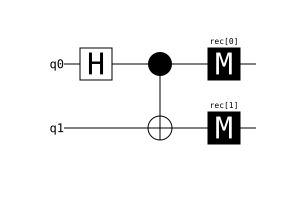

In [3]:
bell = "H 0\nCNOT 0 1\nM 0 1"
r = tool("stim_simulate", circuit=bell, shots=8)
print(r["summary"], "| first shots:", r["samples_preview"][:4])
display(SVG(tool("stim_diagram", circuit=bell)["svg"]))

## 2. Threshold sweep

`threshold_sweep` simulates a code family at several distances and noise rates, decodes with MWPM, and plots logical vs physical error rate. Below threshold, larger distance means fewer logical errors.
**Prompt:** *"Show the threshold of the rotated surface code for d = 3, 5, 7."*

d=3  p=0.003  logical error rate=0.0025
d=3  p=0.006  logical error rate=0.0210
d=3  p=0.010  logical error rate=0.0330
d=5  p=0.003  logical error rate=0.0005
d=5  p=0.006  logical error rate=0.0100
d=5  p=0.010  logical error rate=0.0525
d=7  p=0.003  logical error rate=0.0005
d=7  p=0.006  logical error rate=0.0075
d=7  p=0.010  logical error rate=0.0520


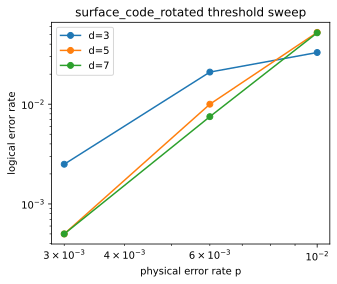

In [4]:
r = tool(
    "threshold_sweep",
    code_family="surface_code_rotated",
    distances=[3, 5, 7],
    p_values=[0.003, 0.006, 0.01],
    shots=2000,
)
for row in r["rows"]:
    print(
        f"d={row['distance']}  p={row['p']:.3f}  logical error rate={row['logical_error_rate']:.4f}"
    )
display(SVG(r["plot_svg"]))

## 3. Beyond Stim's built-in codes (LightStim)

`qec_circuit_build` builds memory circuits for toric, 6.6.6 color, bivariate-bicycle (BB) and PQRM codes. LightStim circuits are noiseless; pass `p` to add uniform circuit-level noise (the same model as Stim's generated circuits). Here: the [[72, 12, 6]] BB code.
**Prompt:** *"Build a noisy memory circuit for the [[72,12,6]] bivariate bicycle code."*

In [5]:
bb = tool("qec_circuit_build", code_family="bb_code", distance=6, rounds=3, p=0.001)
if bb["ok"]:
    print(
        f"qubits={bb['num_qubits']}  detectors={bb['num_detectors']}  "
        f"logical observables={bb['num_observables']}  circuit text={len(bb['circuit_text']):,} bytes"
    )
else:
    print("skipped:", bb["error_message"])

qubits=144  detectors=228  logical observables=12  circuit text=39,720 bytes


## 4. Decoder comparison

`decoder_compare` decodes the **same** syndrome samples with several decoders and ranks them by logical error rate (with standard error and decode time):

| Name | Decoder | Runs on |
|---|---|---|
| `pymatching` | MWPM | CPU, base install |
| `tesseract` | Google's search-based most-likely-error decoder | CPU, `[decoders]` |
| `bposd`, `bplsd`, `belief_find` | `ldpc` BP family via QuEra bloqade-decoders | CPU, `[decoders]` |
| `cudaq_relay_bp`, `cudaq_bposd` | NVIDIA CUDA-Q QEC RelayBP and BP+OSD | GPU, `[cudaq]` |

On the color code, matching only approximates the hyperedges (one error flips three checks), so the other decoders should do much better.
**Prompt:** *"Is Tesseract better than PyMatching for a d=5 color code at p=0.002?"*

In [6]:
def show(result):
    rows = ["| decoder | logical error rate | decode time | note |", "|---|---|---|---|"]
    for r in sorted(result["results"], key=lambda r: (not r["ok"], r["logical_error_rate"])):
        rate = f"{r['logical_error_rate']:.4f} ± {r['std_error']:.4f}" if r["ok"] else "n/a"
        secs = f"{r['decode_seconds']:.2f} s" if r["ok"] else ""
        rows.append(f"| {r['decoder']} | {rate} | {secs} | {r['note']} |")
    display(Markdown("\n".join(rows) + f"\n\n**Best: {result['best']}**"))


cpu = ["pymatching", "tesseract", "bposd", "bplsd"]
show(
    tool(
        "decoder_compare",
        code_family="color_code",
        distance=5,
        p=0.002,
        decoders=cpu,
        shots=2000,
        seed=1,
    )
)

| decoder | logical error rate | decode time | note |
|---|---|---|---|
| tesseract | 0.0050 ± 0.0016 | 7.76 s |  |
| bposd | 0.0075 ± 0.0019 | 1.14 s |  |
| bplsd | 0.0130 ± 0.0025 | 0.56 s |  |
| pymatching | 0.0380 ± 0.0043 | 0.02 s | error model not graphlike; MWPM approximates hyperedges |

**Best: tesseract**

GPU decoders from NVIDIA CUDA-Q QEC. RelayBP should match Tesseract's accuracy in a fraction of the time.
**Prompt:** *"Decode a d=5 color code at p=0.002 with NVIDIA's GPU RelayBP and BP+OSD."*

In [7]:
if CAN["cudaq extra + GPU (RelayBP)"]:
    show(
        tool(
            "decoder_compare",
            code_family="color_code",
            distance=5,
            p=0.002,
            decoders=["pymatching", "tesseract", "cudaq_relay_bp", "cudaq_bposd"],
            shots=2000,
            seed=1,
        )
    )
else:
    print("skipped: needs the [cudaq] extra and an NVIDIA GPU")

| decoder | logical error rate | decode time | note |
|---|---|---|---|
| tesseract | 0.0050 ± 0.0016 | 7.18 s |  |
| cudaq_relay_bp | 0.0050 ± 0.0016 | 0.36 s |  |
| cudaq_bposd | 0.0070 ± 0.0019 | 0.09 s |  |
| pymatching | 0.0380 ± 0.0043 | 0.02 s | error model not graphlike; MWPM approximates hyperedges |

**Best: cudaq_relay_bp**

It also works on qLDPC codes. `decoder_compare` builds LightStim codes itself (`code_family="bb_code"`), so the 84 KB noisy circuit never passes through the chat model. Below: IBM's [[144, 12, 12]] gross code at p = 0.005, where RelayBP should clearly beat BP+OSD (IBM's motivation for RelayBP). Without a GPU, a smaller CPU run is shown instead.
**Prompt:** *"Compare RelayBP and BP+OSD on the gross code at p=0.005."*

In [8]:
if CAN["cudaq extra + GPU (RelayBP)"]:
    show(
        tool(
            "decoder_compare",
            code_family="bb_code",
            distance=12,
            rounds=3,
            p=0.005,
            decoders=["cudaq_relay_bp", "cudaq_bposd"],
            shots=500,
            seed=1,
        )
    )
elif CAN["decoders extra (Tesseract, BP+OSD)"]:
    show(
        tool(
            "decoder_compare",
            code_family="bb_code",
            distance=12,
            rounds=3,
            p=0.003,
            decoders=["bposd", "bplsd"],
            shots=100,
            seed=1,
        )
    )
else:
    print("skipped: needs the [decoders] or [cudaq] extra")

| decoder | logical error rate | decode time | note |
|---|---|---|---|
| cudaq_relay_bp | 0.0000 ± 0.0000 | 5.60 s |  |
| cudaq_bposd | 0.0360 ± 0.0083 | 0.71 s |  |

**Best: cudaq_relay_bp**

## 5. Non-Clifford circuits (QuEra Tsim)

Stim cannot simulate T gates. `tsim_simulate` can. Prepare |+⟩, apply T, measure in the X basis: the detector should fire with probability sin²(π/8) ≈ 0.146. With T then T† it should never fire.
**Prompt:** *"Simulate a T gate on |+> with Tsim and measure in X."*

In [9]:
import math

for label, body in [("T", "T 0"), ("T then T_DAG", "T 0\nT_DAG 0")]:
    r = tool("tsim_simulate", circuit=f"RX 0\n{body}\nMX 0\nDETECTOR rec[-1]", shots=20000)
    if not r["ok"]:
        print("skipped:", r["error_message"])
        break
    print(f"{label:13} detector fired in {r['column_rates'][0]:.3f} of {r['shots']:,} shots")
print(f"theory for T:  sin^2(pi/8) = {math.sin(math.pi / 8) ** 2:.3f}")

T             detector fired in 0.149 of 20,000 shots


T then T_DAG  detector fired in 0.000 of 20,000 shots
theory for T:  sin^2(pi/8) = 0.146


## 6. Shareable visualization (QuEra GLCB)

`glcb_visualize_url` encodes a small circuit as a link to QuEra's Gemini Logical Circuit Builder (diagram, expected values, noise sampling, Bloqade code export). No network call is made.
**Prompt:** *"Give me a GLCB link for a 3-qubit GHZ state."*

In [10]:
ghz = tool(
    "glcb_visualize_url",
    qubits=3,
    gates=[
        {"gate": "h", "column": 0, "targets": [0]},
        {"gate": "cx", "column": 1, "targets": [0, 1]},
        {"gate": "cx", "column": 2, "targets": [1, 2]},
    ],
)
display(
    Markdown(f"[Open the GHZ circuit in GLCB]({ghz['url']})" if ghz["ok"] else ghz["error_message"])
)

[Open the GHZ circuit in GLCB](https://gemini-logical-circuit-builder.vercel.app/#circuit={version:1.1,qubits:3,gates:[{gate:h,column:0,targets:[0]},{gate:cx,column:1,targets:[0,1]},{gate:cx,column:2,targets:[1,2]}],sampler:clifft})

## 7. IBM Quantum hardware

The IBM tools list backends, read calibration, choose the best physical qubits for a circuit, and preview a run. This notebook **never submits a job**; `ibm_submit_execution` exists, but the assistant only uses it after you confirm.
**Prompt:** *"Which IBM backend and qubits give the best fidelity for a 5-qubit GHZ circuit?"*

In [11]:
if CAN["IBM account"]:
    backends = tool("ibm_list_backends")["backends"]
    up = sorted((b for b in backends if b["operational"]), key=lambda b: b["pending_jobs"])
    for b in up[:5]:
        print(f"{b['name']:16} {b['num_qubits']:4} qubits  queue={b['pending_jobs']}")
    m = tool("ibm_map_circuit", circuit_preset="ghz", num_qubits=5)
    print(
        f"\nbest mapping: {m['backend']} qubits {m['physical_qubits']} "
        f"(2q gates={m['transpiled_two_qubit_gate_count']}, est. fidelity={m['estimated_fidelity']:.3f})"
    )
    p = tool(
        "ibm_preview_execution",
        circuit_preset="ghz",
        num_qubits=5,
        backend=m["backend"],
        shots=1000,
    )
    print(
        f"preview: {p['shots']} shots on {p['backend']}, est. fidelity={p['estimated_fidelity']:.3f} (not submitted)"
    )
else:
    print("skipped:", ibm["error_message"])

skipped: This IBM Cloud account has no provisioned Quantum service instance (the token itself is valid). Create one (e.g. the free Open Plan) at https://quantum.cloud.ibm.com/, or if one already exists, set QISKIT_IBM_INSTANCE to its CRN or name.


## 8. Asking ChatQEC

Now the full assistant: question classification, hybrid retrieval over the QEC corpus, tool calls, and a cited answer. This uses the provider in `conf/config.yaml`, or the local test models when `CHATQEC_PROVIDER=local` and `scripts/serve_local_models.sh` is running.

In [12]:
from chatqec.cli import _build_chatqec

if not os.environ.get("CHATQEC_PROVIDER") and CAN["local LLM (Muse-Glimmer)"]:
    os.environ["CHATQEC_PROVIDER"] = "local"  # prefer free local models when they are up
llm_ok = (
    CAN["local LLM (Muse-Glimmer)"]
    or CAN["local LLM (Gemma 4)"]
    or CAN["API keys (Anthropic or Gemini)"]
)
bot = _build_chatqec(mcp_server="chatqec-mcp-tools") if CAN["Qdrant"] and llm_ok else None


def ask(question: str) -> None:
    if bot is None:
        print("skipped: needs Qdrant and an LLM provider")
        return
    a = bot.ask(question)
    display(Markdown(f"**Q:** {question}\n\n{a.text}"))
    for t in a.tool_calls:
        print(f"tool call: {t.name}({json.dumps(t.input)})")
    print(
        f"sources: {', '.join(c.title for c in a.citations) or 'none'}  |  confidence: {a.confidence}"
    )


print("provider:", os.environ.get("CHATQEC_PROVIDER", "from conf/config.yaml"))

provider: local


A conceptual question answered from the corpus, with citations:

In [13]:
ask("Why does minimum-weight perfect matching struggle on color codes?")

**Q:** Why does minimum-weight perfect matching struggle on color codes?

Minimum-weight perfect matching is defined for “graphlike” check structures where every error triggers **at most two** detectors. Decoding then becomes pairing up flipped detectors so that the total weight of the connecting paths is minimized — a minimum-weight perfect matching on the detector graph [^1].

MWPM assumes this graphlike structure:

* “For codes where every error triggers **at most two** detectors (a ‘graphlike’ check structure), the syndrome is a set of flipped detectors.” [^7]
* “MWPM assumes graphlike checks. It is a poor fit for [[qldpc-codes]] and [[color-code|color codes]], whose stabilizers flip more than two detectors per error — those need hyperedge decoders like [[bp-osd-decoder]] or specialized [[color-code-decoders]].” [^1]

The color code violates the graphlike condition:

* “The price is that a single error flips **three** stabilizers, so the syndrome is not graphlike and plain matching does not apply — decoding needs specialized [[color-code-decoders]].” [^2]
* On every face there are two stabilizers — one $X$-type and one $Z$-type — supported on the qubits around that face: $B_f^X = \prod_{v \in f} X_v,\qquad B_f^Z = \prod_{v \in f} Z_v.$ [^2]

Because a single fault can create three syndrome defects rather than two, the syndrome cannot be represented as independent edges between detector pairs. Plain MWPM, which pairs defects via edges, therefore cannot capture the true error correlations and is not applicable without specialized hyperedge decoding.

sources: MWPM Decoder, MWPM Decoder, Color Code  |  confidence: high


A question that needs a computation: the assistant should call `decoder_compare` and report the numbers it got. (Local models sample at their recommended temperature of 1.0, so occasionally the model answers from the corpus instead of calling the tool; rerun the cell if that happens.)

In [14]:
ask(
    "Compare PyMatching, Tesseract and BP+OSD on a distance-5 color code at p=0.002. Which is best?"
)

**Q:** Compare PyMatching, Tesseract and BP+OSD on a distance-5 color code at p=0.002. Which is best?

Minimum-weight perfect matching is built for “graphlike” check structures where every error triggers **at most two** detectors. Then the syndrome is a set of flipped detectors and decoding is pairing them up with minimum total weight – a minimum-weight perfect matching on the detector graph [^3].

The matching picture:

* “For codes where every error triggers **at most two** detectors (a ‘graphlike’ check structure), the syndrome is a set of flipped detectors.” [^3]
* “MWPM assumes graphlike checks. It is a poor fit for [[qldpc-codes]] and [[color-code|color codes]], whose stabilizers flip more than two detectors per error — those need hyperedge decoders like [[bp-osd-decoder]] or specialized [[color-code-decoders]].” [^3]

The color code violates that assumption.

* On *every* face there are two stabilizers — one $X$-type and one $Z$-type — supported on the qubits around that face: $B_f^X = \prod_{v \in f} X_v,\qquad B_f^Z = \prod_{v \in f} Z_v.$ [^2]
* “The price is that a single error flips **three** stabilizers, so the syndrome is not graphlike and plain matching does not apply — decoding needs specialized [[color-code-decoders]].” [^2]

Because a single fault can create three syndrome defects rather than two, the syndrome cannot be represented as independent edges between detector pairs. MWPM, which pairs defects via edges, therefore cannot capture the true error correlations and is not applicable without specialized hyperedge decoding.

### Distance-5 color code, p = 0.002, 2000 shots

Decoder comparison on an identical syndrome sample set:

* **pymatching**: logical error rate $0.040 \pm 0.00438$, 80 errors / 2000 shots, decode 0.22 s. Note: “error model not graphlike; MWPM approximates hyperedges”.
* **tesseract**: logical error rate $0.001 \pm 0.00071$, 2 errors / 2000 shots, decode 11.43 s.
* **bposd**: logical error rate $0.0025 \pm 0.00112$, 5 errors / 2000 shots, decode 1.07 s.

Best under these conditions is tesseract, with BP+OSD second and MWPM far worse, consistent with the non-graphlike nature of the color-code syndrome.

tool call: decoder_compare({"code_family": "color_code", "distance": 5, "p": 0.002, "decoders": ["pymatching", "tesseract", "bposd"], "shots": 2000})
sources: MWPM Decoder, Color Code  |  confidence: medium


## 9. More prompts to try

| Prompt | What you should get |
|---|---|
| *What are the parameters of the gross code?* | [[144, 12, 12]], qubits per logical qubit, check weight, cited |
| *Plot the threshold of the color code for d = 3, 5, 7.* | `threshold_sweep` table and log-log plot, threshold estimate |
| *Simulate a distance-3 surface code memory at p = 0.001.* | `stim_simulate` / `decoder_compare` call and a logical error rate |
| *Which decoder should I use for a BB code, and why?* | BP+OSD or RelayBP over MWPM, with reasons and sources |
| *Run magic-state distillation on a T-gate circuit.* | `tsim_simulate` call with detector statistics |
| *Map a 4-qubit QFT to the best IBM backend.* | backend, physical qubits, estimated fidelity; no job submitted |
| *What is the capital of France?* | politely declined: off-topic for a QEC assistant |


In [15]:
mcp.close()